In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

from telegram_scraper import study, viz
from telegram_scraper.study import CHANNELS, CHANNEL_ORDER, SHORT_NAMES, WINDOW
from telegram_scraper.analysis import stats

viz.apply_style()
np.random.seed(study.SEED)
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
posts = study.load_posts()
events = study.verified_events(posts)
f"{len(posts):,} posts from {posts['channel_slug'].nunique()} channels, {posts['timestamp'].min():%Y-%m-%d} to {posts['timestamp'].max():%Y-%m-%d}"

'12,221 posts from 6 channels, 2026-02-28 to 2026-04-17'

# 01 · Corpus: what is in the data, and what the first pass got wrong

> **Question.** Is the corpus clean enough to compare channels, and how far off was the first-pass file?
>
> **Answer.** Yes after cleaning, and the old file was materially off: in the same 7-14 April window 85% of Press TV posts carry a photo or video (old flag: 64%), 39% carry video (old pipeline: 0%) and 50% have a full text longer than 200 characters (the old file cut every text at 200).

## 1. Messages vs. posts: what album grouping does

Telegram exports every item of an album as its own message, so counting messages double-counts anything posted with several photos or videos. All rates in this study use **posts** (one message, or one whole album). The first figure shows how much that matters for each channel.

,channel_slug,messages,posts,channel,pct_inflation
0,presstv,8574,6683,Press TV,0.282957
1,irna-en,2010,1637,IRNA,0.227856
2,idfofficial,1429,1429,IDF,0.000000
3,iltvnews,691,556,ILTV,0.242806
4,thetimesofisrael2022,622,622,ToI,0.000000
5,jewishbreakingnewstelegram,1294,1294,JBN,0.000000


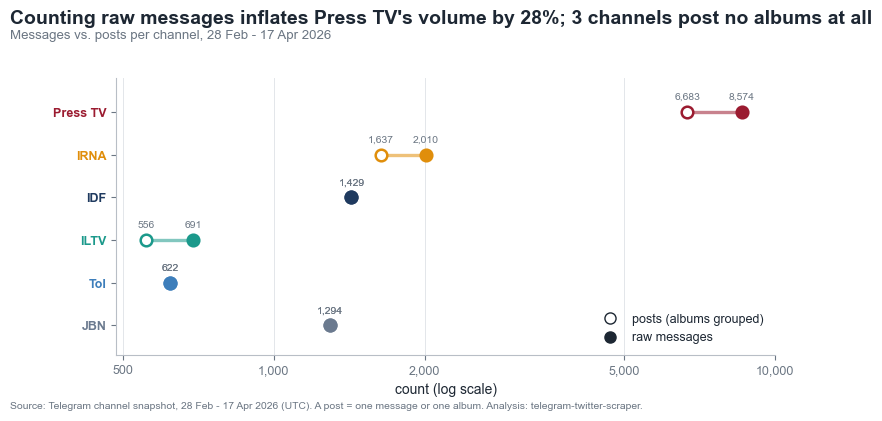

In [2]:
messages = study.load_snapshot(study.SNAPSHOT_DIR)
grouping = pd.DataFrame({
    "channel_slug": CHANNEL_ORDER,
    "messages": messages.groupby("channel_slug").size().reindex(CHANNEL_ORDER).to_numpy(),
    "posts": posts.groupby("channel_slug").size().reindex(CHANNEL_ORDER).to_numpy(),
})
grouping["channel"] = grouping["channel_slug"].map(SHORT_NAMES)
grouping["pct_inflation"] = grouping["messages"] / grouping["posts"] - 1
display(grouping)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
viz.dumbbell(ax, grouping, label_col="channel", start_col="posts", end_col="messages",
             start_label="posts (albums grouped)", end_label="raw messages", value_fmt="{:,.0f}")
ax.set_xscale("log"); ax.set_xlabel("count (log scale)")
ax.set_xticks([500, 1000, 2000, 5000, 10000]); ax.set_xticklabels(["500", "1,000", "2,000", "5,000", "10,000"]); ax.minorticks_off()
top = grouping.sort_values("pct_inflation").iloc[-1]
viz.headline(fig, f"Counting raw messages inflates {top['channel']}'s volume by {top['pct_inflation']:.0%}; {int((grouping['pct_inflation'] == 0).sum())} channels post no albums at all",
             "Messages vs. posts per channel, 28 Feb - 17 Apr 2026")
viz.done(fig, "01_album_grouping", grouping)

**Reading the figure.** Counting messages instead of posts inflates Press TV by 28%, ILTV by 24% and IRNA by 23%; the IDF, ToI and JBN post no albums, so for them messages and posts are identical. A comparison of raw message counts would therefore have exaggerated Press TV's lead over ToI, IDF and JBN by roughly a quarter.

## 2. Which kinds of media each channel attaches

A post's editorial media class is **video** (any video or animation in the post) > **photo** > **link preview** (a web-page card, which is *not* editorial media) > **text only**. This ordering matters: the first-pass analysis coded media from a photo-only flag, so every video post was silently counted as text-only.

media_class,video,photo,link preview,text only,total
channel_slug,,,,,
presstv,3185,2997,391,110,6683
irna-en,188,850,370,229,1637
idfofficial,0,4,187,1238,1429
iltvnews,289,206,0,61,556
thetimesofisrael2022,0,621,1,0,622
jewishbreakingnewstelegram,572,581,0,141,1294


media_class,video,photo,link preview,text only
channel_slug,,,,
presstv,47.7,44.8,5.9,1.6
irna-en,11.5,51.9,22.6,14.0
idfofficial,0.0,0.3,13.1,86.6
iltvnews,52.0,37.1,0.0,11.0
thetimesofisrael2022,0.0,99.8,0.2,0.0
jewishbreakingnewstelegram,44.2,44.9,0.0,10.9


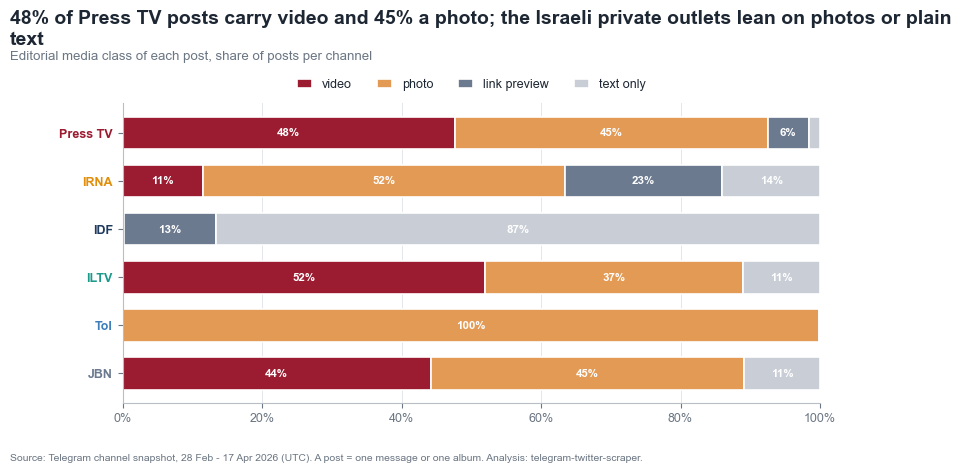

In [3]:
media_counts = pd.crosstab(posts["channel_slug"], posts["media_class"]).reindex(CHANNEL_ORDER)
media_counts = media_counts.reindex(columns=[c for c in study.MEDIA_CLASSES if c in media_counts.columns])
media_shares = media_counts.div(media_counts.sum(axis=1), axis=0)
display(media_counts.assign(total=media_counts.sum(axis=1)))
display((media_shares * 100).round(1))

palette = {"video": "#9B1B30", "photo": "#E39A55", "link preview": "#6B7A8F", "other media": "#B9A27A", "text only": "#C9CED6"}
fig, ax = plt.subplots(figsize=(9, 3.9))
viz.stacked_share_bars(ax, media_shares, colors=palette, label_min=0.05)
pt = media_shares.loc["presstv"]
viz.headline(fig, f"{pt['video']:.0%} of Press TV posts carry video and {pt['photo']:.0%} a photo; the Israeli private outlets lean on photos or plain text",
             "Editorial media class of each post, share of posts per channel")
viz.done(fig, "01_media_mix", media_shares.reset_index().melt(id_vars="channel_slug", var_name="media_class", value_name="share").merge(
    media_counts.reset_index().melt(id_vars="channel_slug", var_name="media_class", value_name="n"), on=["channel_slug", "media_class"]))

**Reading the figure.** Press TV is 48% video, 45% photo, 6% link-preview cards and only 1.6% text-only. That is not unusual among the *news-brand* channels: ILTV is 52% video and JBN 44%. The channels that look different are the IDF (87% text-only, 13% link cards) and ToI (99.8% photo: every post is a headline image with a "Read more" link) and IRNA (52% photo, 23% link cards, 14% text-only). So "heavy use of video" cannot be a Press TV or state-broadcaster signature; "almost never plain text" is closer, but only Press TV (1.6%) and ToI (0%) share it, while ILTV, JBN and IRNA post plain text 11-14% of the time.

## 3. How long are the posts?

Text length separates a headline-and-link outlet from a wire-style channel. Lengths below are **full** text after boilerplate cleaning (nothing is truncated; the first pass cut every text at 200 characters).

,channel,count,mean,std,min,25%,50%,75%,90%,max
channel_slug,,,,,,,,,,
presstv,Press TV,6619.0,197.0,151.0,6.0,103.0,167.0,261.0,329.0,3987.0
irna-en,IRNA,1635.0,677.0,801.0,22.0,212.0,289.0,972.0,1843.0,3915.0
idfofficial,IDF,1425.0,656.0,548.0,33.0,238.0,642.0,768.0,1292.0,4088.0
iltvnews,ILTV,542.0,314.0,225.0,3.0,112.0,315.0,462.0,592.0,2200.0
thetimesofisrael2022,ToI,622.0,148.0,86.0,34.0,81.0,99.0,250.0,270.0,431.0
jewishbreakingnewstelegram,JBN,1113.0,349.0,275.0,16.0,150.0,259.0,472.0,699.0,2278.0


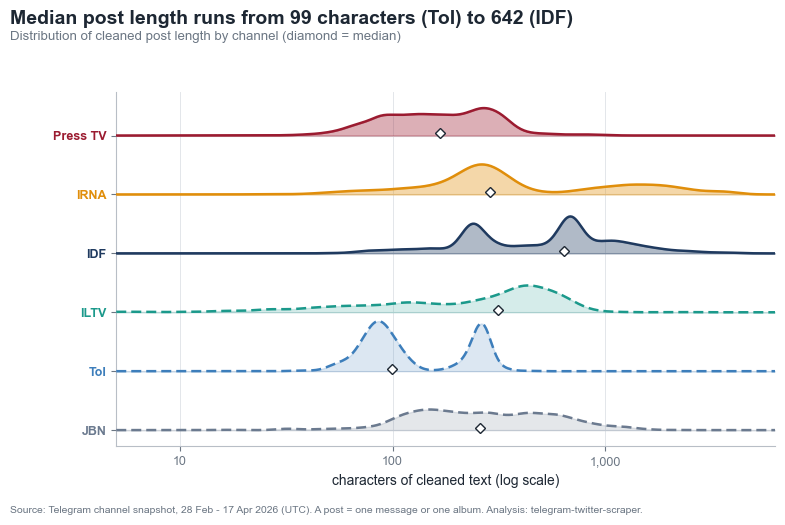

In [4]:
has_text = posts[posts["has_clean_text"]].copy()
has_text["clean_len"] = has_text["clean_text"].str.len()
length_summary = has_text.groupby("channel_slug")["clean_len"].describe(percentiles=[.25, .5, .75, .9]).reindex(CHANNEL_ORDER)
length_summary.insert(0, "channel", [SHORT_NAMES[s] for s in length_summary.index])
display(length_summary.round(0))

samples = {s: np.log10(g["clean_len"].clip(lower=1)) for s, g in has_text.groupby("channel_slug")}
medians = has_text.groupby("channel_slug")["clean_len"].median()
fig, ax = plt.subplots(figsize=(8.5, 4.6))
viz.ridgeline(ax, samples, xlim=(0.7, 3.8), bw=0.15, xlabel="characters of cleaned text (log scale)",
              means={s: (np.log10(medians[s]),) * 3 for s in medians.index})
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["10", "100", "1,000"])
longest = medians.idxmax(); shortest = medians.idxmin()
viz.headline(fig, f"Median post length runs from {medians[shortest]:.0f} characters ({SHORT_NAMES[shortest]}) to {medians[longest]:.0f} ({SHORT_NAMES[longest]})",
             "Distribution of cleaned post length by channel (diamond = median)")
viz.done(fig, "01_text_length", length_summary.reset_index().rename(columns={"index": "channel_slug"}))

**Reading the figure.** Median cleaned text length is 99 characters at ToI (headline only), 167 at Press TV, 259 at JBN, 289 at IRNA, 315 at ILTV and 642 at the IDF. The IDF and IRNA distributions have a long second hump above 1,000 characters (communiqués and wire-style stories); Press TV is short and tightly packed (90th percentile 329 characters). Length differences are large, so any word-count or n-gram comparison must be normalised per post.

## 4. Boilerplate cleaning: what is stripped and why

Channels append sign-offs and calls to action to nearly every post (`@PressTV`, WhatsApp/"JBN links" blocks, ToI's "Read more" link). Left in, these would dominate word-level and topic analyses and make posts from the same channel look alike for the wrong reason. `study.clean_text` removes **only** that boilerplate; content words are never altered. Every rule is listed here, then shown on real posts.

In [5]:
rules = pd.DataFrame(
    [{"channel": SHORT_NAMES[slug], "rule": name, "regex": pattern.pattern, "what it removes": desc}
     for slug, items in study.BOILERPLATE_RULES.items() for name, pattern, _, desc in items]
)
with pd.option_context("display.max_colwidth", 120):
    display(rules)
display(pd.DataFrame(study.GENERIC_RULES, columns=["generic pass (all channels)", "effect"]))

,channel,rule,regex,what it removes
0,Press TV,presstv_handle_line,(?m)^[ \t]*(?:[^\w\s@#]+[ \t]*)?(?:@\w+[ \t]*)+$,"Line that is only @handles (sign-off '@PressTV', '@Unscripted_PTV', '@PalestineDeclassified', ...)"
1,Press TV,presstv_trailing_handle,[ \t]*@(?:PressTV|Press_TV)\b[ \t]*$,'@PressTV' sign-off at the end of a content line
2,Press TV,presstv_watch_in_full,(?im)^[ \t]*(?:[^\w\s]+[ \t]*)?watch (?:in full|the full|full)(?: here)?[ \t]*:?[ \t]*$,'Watch in full (here)' call to action
3,Press TV,presstv_hashtag_line,(?m)^[ \t]*(?:#\w+[ \t]*)+$,Line that is only #hashtags (programme tags such as #IranToday)
4,Press TV,presstv_khamenei_ir_footer,(?im)^.*KHAMENEI\.IR.*$,'KHAMENEI.IR | X (Official)' footer line on reposted Leader statements
5,IRNA,irna_handle_line,(?m)^[ \t]*(?:[^\w\s@#]+[ \t]*)?(?:@\w+[ \t]*)+$,"Line that is only @Irna_en (sign-off, usually after an emoji)"
6,IRNA,irna_dateline,"(?m)^([ \t]*)(?:[^\w\s]+[ \t]*)?[A-Z][A-Za-z .'-]{1,30},[ \t]*IRNA[ \t]*[-–—]+[ \t]*","Dateline prefix 'Tehran, IRNA -' (the sentence continues after it)"
7,JBN,jbn_cta_line,(?im)^.*(?:whatsapp (?:group|channel)|follow all jbn links|see all jbn links|donate now|tax deductible|\u2611\ufe0f?...,WhatsApp / 'JBN links' / donate / tax-deductible / verified-badge / 'Read ... >>>' call-to-action lines
8,JBN,jbn_telegram_link_line,(?im)^[ \t]*(?:[^\w\s]+[ \t]*)*telegram[ \t]*(?:[^\w\s]+[ \t]*)*(?:https?://\S*)?[ \t]*$,"'TELEGRAM <link>' follow line (only an emoji, the word TELEGRAM and a link)"
9,JBN,jbn_read_more_link,(?im)^[ \t]*(?:[^\w\s]+[ \t]*)?read (?:more|the (?:full )?(?:story|details))\b[^\n]*$,'READ MORE: <link>' line pointing to jewishbreakingnews.com


,generic pass (all channels),effect
0,zero_width,[​‌‍‎‏⁠﻿] -> '' (zero-width / bidi marks; IRNA pads lines with U+200B)
1,urls,"(?:https?://|www\.|t\.me/|toi\.li/)\S* -> '' (bare URLs, incl. toi.li short links)"
2,leading_emoji,"emoji / pictograph markers at the start of a line are removed (decorative bullets like pin, warning)"
3,no_letter_lines,"lines with no letter or digit at all (emoji-only, punctuation-only) are dropped"
4,whitespace,runs of blank lines collapse to one blank line; spaces collapse; text is stripped


In [6]:
rng = np.random.default_rng(study.SEED)
changed = posts[(posts["text"].str.strip() != posts["clean_text"]) & posts["has_clean_text"]]
for slug in CHANNEL_ORDER:
    pool = changed[changed["channel_slug"] == slug]
    if pool.empty:
        continue
    sample = pool.iloc[rng.choice(len(pool), size=min(2, len(pool)), replace=False)]
    print("=" * 100); print(CHANNELS[slug]["name"], f"- {len(pool)} of {int((posts['channel_slug'] == slug).sum())} posts were changed by cleaning")
    for row in sample.itertuples():
        print("-" * 100); print("BEFORE:", repr(row.text[:420])); print("AFTER :", repr(row.clean_text[:420]))

Press TV - 6593 of 6683 posts were changed by cleaning
----------------------------------------------------------------------------------------------------
BEFORE: '🔺 Reports indicate that the Dubai International Airport suffers approximately one million dollars in economic losses for every minute it remains closed. According to these assessments, a full 24-hour closure of the airport could result in a staggering daily loss of $1.44 billion.\n\n@PressTV'
AFTER : 'Reports indicate that the Dubai International Airport suffers approximately one million dollars in economic losses for every minute it remains closed. According to these assessments, a full 24-hour closure of the airport could result in a staggering daily loss of $1.44 billion.'
----------------------------------------------------------------------------------------------------
BEFORE: "It's either security for all or security for none, warns Iraq's Kataeb Hezbollah\n\nThe Secretary General of Iraq’s Kataeb Hezbollah, Abu Huss

,raw_chars,clean_chars,posts,posts_with_text,raw_has_text,pct_chars_removed,posts_emptied_by_cleaning,channel
channel_slug,,,,,,,,
presstv,1396892,1302915,6683,6619,6619,0.067276,0,Press TV
irna-en,1153058,1107570,1637,1635,1635,0.039450,0,IRNA
idfofficial,1007100,934629,1429,1425,1429,0.071960,4,IDF
iltvnews,172071,170247,556,542,551,0.010600,9,ILTV
thetimesofisrael2022,113187,92070,622,622,622,0.186567,0,ToI
jewishbreakingnewstelegram,643412,388715,1294,1113,1119,0.395854,6,JBN


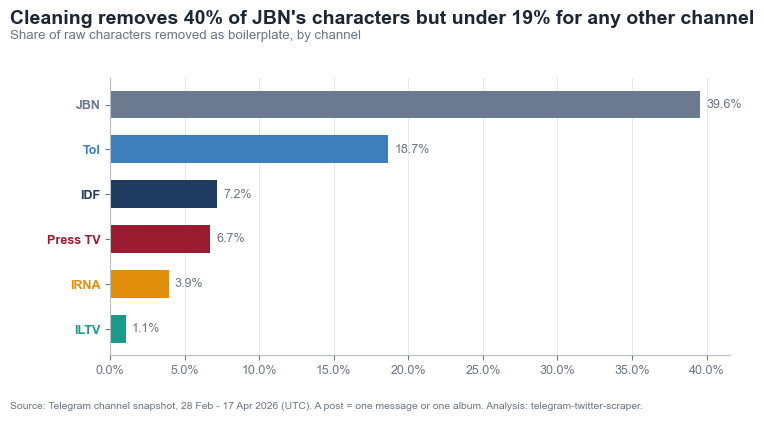

In [7]:
removed = (
    posts.assign(raw_len=posts["text"].str.len(), clean_len=posts["clean_text"].str.len())
    .groupby("channel_slug").agg(raw_chars=("raw_len", "sum"), clean_chars=("clean_len", "sum"),
                                 posts=("post_id", "size"), posts_with_text=("has_clean_text", "sum"),
                                 raw_has_text=("text", lambda s: int((s.str.strip() != "").sum())))
    .reindex(CHANNEL_ORDER)
)
removed["pct_chars_removed"] = 1 - removed["clean_chars"] / removed["raw_chars"]
removed["posts_emptied_by_cleaning"] = removed["raw_has_text"] - removed["posts_with_text"]
removed["channel"] = [SHORT_NAMES[s] for s in removed.index]
display(removed)

fig, ax = plt.subplots(figsize=(8, 3.6))
order = removed.sort_values("pct_chars_removed")
ax.barh([SHORT_NAMES[s] for s in order.index], order["pct_chars_removed"], color=[viz.CHANNEL_COLORS[s] for s in order.index], height=0.62)
for y, v in enumerate(order["pct_chars_removed"]):
    ax.text(v + 0.004, y, f"{v:.1%}", va="center", fontsize=9, color=viz.MUTED)
ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.grid(axis="y", visible=False)
viz.color_channel_ticklabels(ax)
worst = order.iloc[-1]
viz.headline(fig, f"Cleaning removes {worst['pct_chars_removed']:.0%} of {worst['channel']}'s characters but under {order['pct_chars_removed'].iloc[:-1].max():.0%} for any other channel",
             "Share of raw characters removed as boilerplate, by channel")
viz.done(fig, "01_boilerplate_share", removed.reset_index())

**Reading the table and examples.** Cleaning removes 40% of JBN's characters (its WhatsApp / "JBN links" / donate block follows almost every post), 19% of ToI's ("Read more" link line), 7% of the IDF's and Press TV's, 4% of IRNA's and 1% of ILTV's. Nine ILTV posts, six JBN posts and four IDF posts consist of nothing but boilerplate and drop out of text analyses (their media still counts). Spot-check the BEFORE/AFTER pairs above: only sign-offs, emoji bullets, links and datelines disappear.

One thing cleaning deliberately does **not** do: the IDF repeats near-identical Home Front Command alert texts. 46% of IDF posts are exact duplicates of another IDF post, against 2-5% at Press TV, IRNA, ILTV and JBN. These are real output, so they stay in, but they shape the IDF's topic profile (notebook 03) and tone (notebook 05), and both notebooks check what happens without them.

## 5. Corrections to the first pass

The first-pass article was built from `messages.csv`: 1,200 Press TV messages from 7-14 April, each text cut at 200 characters, with a `has_media` flag that only counted photos. The frozen snapshot lets us re-measure exactly the same window and see what those two defects hid.

,metric,first_pass,now,note,channel_slug
0,Press TV items flagged as having media,0.635,0.854470,old flag = photo only; now photo OR video,presstv
1,Press TV posts that carry a video,0.000,0.387734,old pipeline had no video flag at all,presstv
2,texts cut at the 200-character cap,0.405,0.502079,share whose FULL text exceeds 200 chars,presstv


same window (Apr 07 06:13 - Apr 14 16:59 UTC): old file 1,200 messages; snapshot 1,200 messages = 962 posts
old file max text length: 200; snapshot max text length in window: 4005
Press TV posts in window with no editorial media: 140 (14.6%); old file counted 36.5% as text-only


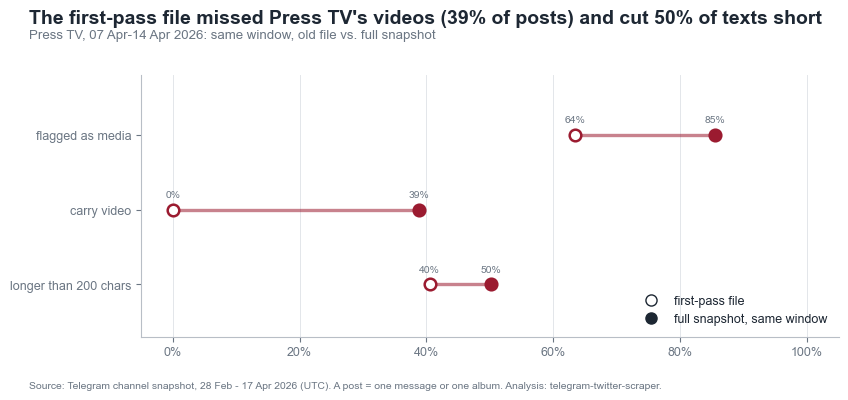

In [8]:
old = pd.read_csv(study.ROOT / "archive/2026-04-first-pass/notebooks/messages.csv", parse_dates=["timestamp"])
old_start, old_end = old["timestamp"].min(), old["timestamp"].max()
same = posts[(posts["channel_slug"] == "presstv") & posts["timestamp"].between(old_start, old_end)]
raw_same = messages[(messages["channel_slug"] == "presstv") & messages["timestamp"].between(old_start, old_end)]
old_len = old["text"].fillna("").str.len()
corr = pd.DataFrame([
    {"metric": "Press TV items flagged as having media", "first_pass": old["has_media"].mean(),
     "now": same["has_editorial_media"].mean(), "note": "old flag = photo only; now photo OR video"},
    {"metric": "Press TV posts that carry a video", "first_pass": 0.0, "now": same["has_video"].mean(),
     "note": "old pipeline had no video flag at all"},
    {"metric": "texts cut at the 200-character cap", "first_pass": float((old_len >= 200).mean()),
     "now": float((same["text_len"] > 200).mean()), "note": "share whose FULL text exceeds 200 chars"},
])
corr["channel_slug"] = "presstv"
display(corr)
print(f"same window ({old_start:%b %d %H:%M} - {old_end:%b %d %H:%M} UTC): old file {len(old):,} messages; snapshot {len(raw_same):,} messages = {len(same):,} posts")
print(f"old file max text length: {int(old_len.max())}; snapshot max text length in window: {int(same['text_len'].max())}")
print(f"Press TV posts in window with no editorial media: {(~same['has_editorial_media']).sum()} ({(~same['has_editorial_media']).mean():.1%}); old file counted {(~old['has_media']).mean():.1%} as text-only")

fig, ax = plt.subplots(figsize=(9, 3.4))
plot_df = corr.assign(label=["flagged as media", "carry video", "longer than 200 chars"])
viz.dumbbell(ax, plot_df, label_col="label", start_col="first_pass", end_col="now", start_label="first-pass file", end_label="full snapshot, same window", value_fmt="{:.0%}")
ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.set_xlim(-0.05, 1.05)
viz.headline(fig, f"The first-pass file missed Press TV's videos ({corr.loc[1, 'now']:.0%} of posts) and cut {corr.loc[2, 'now']:.0%} of texts short",
             f"Press TV, {old_start:%d %b}-{old_end:%d %b} 2026: same window, old file vs. full snapshot")
viz.done(fig, "01_first_pass_corrections", corr)

**Reading the figure.** Three corrections for the same 8-day Press TV window (1,200 messages = 962 posts):

- *Media.* The old flag counted photos only: 64% of messages "had media". With videos counted, 85% of posts have editorial media and 39% carry video. Text-only posts are 15% of posts, not the 36% the old file implied, so the "media vs text-only" contrast in the first pass compared photos with a mix of videos, link cards and genuinely plain text.
- *Truncation.* Every old text was capped at 200 characters and 41% of messages hit the cap; with full text, 50% of the window's posts exceed 200 characters and the longest is 4,005.
- *Unit.* 1,200 messages are 962 posts.

Anything in the first-pass article that depended on media flags, text length or word-level content of Press TV should be treated as unverified.

## 6. Events: only the ones the data supports

Later notebooks mark events on timelines. An event is drawn only if its evidence query matches at least 8 posts from at least 2 channels within ±1 day of its date. Anything the data does not support is dropped, not asserted from memory. Up to three matching posts per event are printed so the match can be eyeballed.

In [9]:
verdict = study.verify_events(posts)
display(verdict)
print("verified:", [e["key"] for e in events]); print("dropped :", [e["key"] for e in study.EVENTS if e not in events])
for event in study.EVENTS:
    print("=" * 100); print(event["date"], "-", event["label"], "| query:", event["evidence_query"])
    for row in study.event_examples(posts, event, n=3).itertuples():
        print(f"  [{row.timestamp:%m-%d %H:%M}] {row.short_name:>8}: {row.clean_text[:170]!r}")

,key,date,label,n_matches,n_channels,Press TV,IRNA,IDF,ILTV,ToI,JBN,verified
0,war_start,2026-02-28,US-Israeli strikes on Iran begin,102,6,44,27,11,8,5,7,True
1,khamenei_death,2026-03-01,Khamenei's death announced,75,5,25,29,0,6,8,7,True
2,ceasefire,2026-04-08,US-Iran ceasefire announced,157,6,88,35,4,5,9,16,True
3,mourning_40,2026-04-09,40th-day mourning for Khamenei,70,2,48,22,0,0,0,0,True
4,islamabad,2026-04-11,Islamabad Iran-US talks,102,5,69,25,0,1,2,5,True
5,hormuz_blockade,2026-04-13,US naval blockade of Hormuz,51,5,35,4,0,4,4,4,True
6,yom_hashoah,2026-04-14,Yom HaShoah (Holocaust Remembrance Day),28,5,2,0,4,5,12,5,True


verified: ['war_start', 'khamenei_death', 'ceasefire', 'mourning_40', 'islamabad', 'hormuz_blockade', 'yom_hashoah']
dropped : []
2026-02-28 - US-Israeli strikes on Iran begin | query: Roaring Lion|(?:strikes?|attacks?|attacked|struck|bombed) (?:on |against )?Iran|US-Israeli (?:aggression|attack|strikes?)|Israel has launched


  [02-28 06:24]      ToI: 'Israel has launched a preemptive attack on Iran, Defense Minister Katz says; sirens sound across Israel'
  [02-28 06:30] Press TV: 'Multiple explosions reported across Tehran.\n\nIsraeli regime says launched attacks on Iran'
  [02-28 07:07]     IRNA: 'The Israeli regime has claimed the responsibility of Saturday attack on Iran.'
2026-03-01 - Khamenei's death announced | query: Khamenei.{0,60}(?:dead|death|martyr|killed|funeral)|(?:death|martyrdom|assassination|killing) of .{0,40}Khamenei
  [02-28 14:03]     ILTV: 'Israeli media reports say Israel assesses Iran’s Supreme Leader Ali Khamenei was likely killed in an Israeli strike earlier today, citing unnamed sources and “growing ind'
  [02-28 19:36]      ToI: 'Israeli official: Khamenei was killed in Israeli airstrike'
  [03-01 00:28]      JBN: 'Iranian Leader Khamenei is Dead: Ayatollah Ali Khamenei, Iran’s supreme leader who ruled the country for almost four decades, has been killed, according to US Presiden

  [04-08 06:46] Press TV: "Feature - Leader's 40th day of martyrdom seals US defeat: A look at his 37-year illustrious legacy\n\nFrom seminary to battlefield, presidency to Leadership, Ayatollah Seyy"
  [04-08 09:12]     IRNA: '‘School of Khamenei’ cause of Iran’s victory in 40-day war: Vice president\n\nVice President Mohammad Reza Aref has hailed the “proud and historic” victory in the 40-day wa'
2026-04-11 - Islamabad Iran-US talks | query: Islamabad
  [04-10 03:33] Press TV: 'Pakistani defense minister blasts Israel over genocide in Lebanon\n\nPakistan’s Defense Minister Khawaja Muhammad Asif has blasted the Israeli regime as “evil and a curse f'
  [04-10 05:33]     IRNA: 'Araghchi: Iran ready if US wishes to crater its economy by letting Netanyahu ‘kill diplomacy’\n\nForeign Minister Abbas Araghchi has emphasized that if the US wishes to cra'
  [04-10 14:08]      JBN: 'JUST IN: U.S. Vice President JD Vance has departed Joint Base Andrews en route to Islamabad, Pakistan, where he i

**Reading the table.** All seven candidate events are supported by the posts themselves (at least 8 matching posts from at least 2 channels within ±1 day), so none was dropped. Two details matter for how the events are described:

- *Khamenei's death* is dated 1 Mar, when Iranian state outlets confirmed it (Press TV 01:28 and IRNA 01:49 UTC), but the Israeli channels were already reporting it as likely on 28 Feb (ILTV 14:03 UTC, ToI 19:36 UTC).
- *The 40th-day mourning* (9 Apr) is evidenced almost entirely by Iranian channels (Press TV 63 posts, IRNA 36 and 2 from JBN), and *Yom HaShoah* (14 Apr) mostly by the Israeli ones (ToI 12, ILTV 5, JBN 5, IDF 4; two Press TV posts mention the Holocaust in another context). Which events a channel marks is itself data; notebook 03 measures it.

"Verified" means the topic was being posted about on that date, not that the event is independently confirmed.

In [10]:
_ = study.record_findings("01_corpus", {
    "messages_vs_posts": grouping[["channel_slug", "messages", "posts", "pct_inflation"]],
    "media_class_shares": media_shares.reset_index(),
    "media_class_counts": media_counts.reset_index(),
    "median_clean_text_len": medians,
    "pct_chars_removed_by_cleaning": removed["pct_chars_removed"],
    "first_pass_corrections": corr.drop(columns="channel_slug"),
    "first_pass_window": [str(old_start), str(old_end)],
    "events_verified": verdict,
    "events_dropped": [e["key"] for e in study.EVENTS if e not in events],
})

## What this means for the article

- **Replace first-pass numbers that came from `messages.csv`.** Video share, text-only share, text lengths and anything keyed to the 200-character texts are superseded by the full-text snapshot.
- **Describe the unit once**: a *post* is one message or one album.
- **Boilerplate is not content.** If the article quotes word counts or "signature phrases", say that sign-offs, "Read more" lines and JBN's follow/donate block were removed first; without that, JBN's and ToI's vocabularies would be dominated by their own calls to action.
- **Use only the seven verified event dates** (all pass), and describe them as "topics spiking in the channels' own posts".
- **Caveat the IDF's templated alerts** whenever the IDF is compared with anything: nearly half of its posts are repeats.